### **1.Data Loading and Initial Inspection**

In [2]:

# Import libraries
import pandas as pd
import numpy as np
from pathlib import Path

# Define the project and dataset paths
PROJECT_ROOT = Path.cwd().parent
DATA_PATH = PROJECT_ROOT / "data" / "raw" / "Online Retail.xlsx"

# Check whether the file exists
print("Dataset path:", DATA_PATH)
print("File exists:", DATA_PATH.exists())

# Load the dataset
if not DATA_PATH.exists():
    raise FileNotFoundError(
        f"Dataset not found at {DATA_PATH}. "
        "Check your folder structure and filename."
    )

df = pd.read_excel(DATA_PATH, engine="openpyxl")

# Inspect the dataset
print("\nDataset loaded successfully!")
print("Shape:", df.shape)

print("\nFirst 5 rows:")
display(df.head())

print("\nColumn names:")
print(df.columns.tolist())

print("\nData types:")
print(df.dtypes)

print("\nDataset information:")
df.info()


Dataset path: d:\StockSense_AI\data\raw\Online Retail.xlsx
File exists: True

Dataset loaded successfully!
Shape: (541909, 8)

First 5 rows:


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom



Column names:
['InvoiceNo', 'StockCode', 'Description', 'Quantity', 'InvoiceDate', 'UnitPrice', 'CustomerID', 'Country']

Data types:
InvoiceNo              object
StockCode              object
Description            object
Quantity                int64
InvoiceDate    datetime64[us]
UnitPrice             float64
CustomerID            float64
Country                   str
dtype: object

Dataset information:
<class 'pandas.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   InvoiceNo    541909 non-null  object        
 1   StockCode    541909 non-null  object        
 2   Description  540455 non-null  object        
 3   Quantity     541909 non-null  int64         
 4   InvoiceDate  541909 non-null  datetime64[us]
 5   UnitPrice    541909 non-null  float64       
 6   CustomerID   406829 non-null  float64       
 7   Country      541909 non-null  str  

In [3]:
df.shape

(541909, 8)

In [4]:

# Missing values
print("Missing values per column:")
display(df.isnull().sum().sort_values(ascending=False))

# Duplicate rows
print("\nNumber of duplicate rows:")
print(df.duplicated().sum())

# Basic statistical summary
print("\nNumerical summary:")
display(df.describe().T)

# Unique values in important columns
for col in ["InvoiceNo", "StockCode", "CustomerID", "Country"]:
    print(f"\nUnique values in {col}:")
    print(df[col].nunique(dropna=True))

# Inspect quantity and unit price
print("\nQuantity summary:")
print(df["Quantity"].describe())

print("\nUnit price summary:")
print(df["UnitPrice"].describe())

# Inspect invoice dates
print("\nInvoiceDate data type:")
print(df["InvoiceDate"].dtype)

print("\nInvoice date range:")
print(df["InvoiceDate"].min(), "to", df["InvoiceDate"].max())


Missing values per column:


CustomerID     135080
Description      1454
StockCode           0
InvoiceNo           0
Quantity            0
InvoiceDate         0
UnitPrice           0
Country             0
dtype: int64


Number of duplicate rows:
5268

Numerical summary:


,count,mean,min,25%,50%,75%,max,std
Quantity,541909.0,9.55225,-80995.0,1.0,3.0,10.0,80995.0,218.081158
InvoiceDate,541909,2011-07-04 13:34:57.156386,2010-12-01 08:26:00,2011-03-28 11:34:00,2011-07-19 17:17:00,2011-10-19 11:27:00,2011-12-09 12:50:00,NaN
UnitPrice,541909.0,4.611114,-11062.06,1.25,2.08,4.13,38970.0,96.759853
CustomerID,406829.0,15287.69057,12346.0,13953.0,15152.0,16791.0,18287.0,1713.600303



Unique values in InvoiceNo:
25900

Unique values in StockCode:
4070

Unique values in CustomerID:
4372

Unique values in Country:
38

Quantity summary:
count    541909.000000
mean          9.552250
std         218.081158
min      -80995.000000
25%           1.000000
50%           3.000000
75%          10.000000
max       80995.000000
Name: Quantity, dtype: float64

Unit price summary:
count    541909.000000
mean          4.611114
std          96.759853
min      -11062.060000
25%           1.250000
50%           2.080000
75%           4.130000
max       38970.000000
Name: UnitPrice, dtype: float64

InvoiceDate data type:
datetime64[us]

Invoice date range:
2010-12-01 08:26:00 to 2011-12-09 12:50:00


### **Exploratory Data Analysis**

In [5]:

import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

# Work on a copy so the original data remains unchanged
eda_df = df.copy()

# Identify cancellation invoices
eda_df["IsCancellation"] = (
    eda_df["InvoiceNo"].astype(str).str.startswith("C")
)

# Calculate line value, not profit
eda_df["LineValue"] = (
    eda_df["Quantity"] * eda_df["UnitPrice"]
)

# Identify unusual transaction records
eda_df["IsNegativeQuantity"] = eda_df["Quantity"] < 0
eda_df["IsNegativePrice"] = eda_df["UnitPrice"] < 0
eda_df["IsZeroPrice"] = eda_df["UnitPrice"] == 0

print("Total rows:", len(eda_df))
print("Cancellation invoice rows:", eda_df["IsCancellation"].sum())
print("Negative quantity rows:", eda_df["IsNegativeQuantity"].sum())
print("Negative unit price rows:", eda_df["IsNegativePrice"].sum())
print("Zero unit price rows:", eda_df["IsZeroPrice"].sum())

print("\nTotal line value, including all records:")
print(round(eda_df["LineValue"].sum(), 2))

print("\nUnique invoice count:", eda_df["InvoiceNo"].nunique())
print("Unique product codes:", eda_df["StockCode"].nunique())


Total rows: 541909
Cancellation invoice rows: 9288
Negative quantity rows: 10624
Negative unit price rows: 2
Zero unit price rows: 2515

Total line value, including all records:
9747747.93

Unique invoice count: 25900
Unique product codes: 4070


In [6]:

# Missing-value percentages
missing_summary = pd.DataFrame({
    "Missing Count": eda_df.isnull().sum(),
    "Missing Percentage": (
        eda_df.isnull().mean() * 100
    ).round(2)
})

display(missing_summary.sort_values(
    "Missing Count", ascending=False
))

# Inspect duplicate rows
duplicate_rows = eda_df[eda_df.duplicated(keep=False)]

print("Rows involved in duplicate groups:", len(duplicate_rows))
display(duplicate_rows.head(10))

# Compare transaction characteristics
print("\nCancellation vs non-cancellation:")
display(
    eda_df.groupby("IsCancellation").agg(
        Rows=("InvoiceNo", "size"),
        Invoices=("InvoiceNo", "nunique"),
        TotalQuantity=("Quantity", "sum"),
        TotalLineValue=("LineValue", "sum")
    )
)

# Inspect negative-quantity records
print("\nExamples of negative-quantity transactions:")
display(
    eda_df.loc[
        eda_df["Quantity"] < 0,
        ["InvoiceNo", "StockCode", "Description",
         "Quantity", "InvoiceDate", "UnitPrice"]
    ].head(10)
)


,Missing Count,Missing Percentage
CustomerID,135080,24.93
Description,1454,0.27
InvoiceNo,0,0.00
Quantity,0,0.00
StockCode,0,0.00
InvoiceDate,0,0.00
UnitPrice,0,0.00
Country,0,0.00
IsCancellation,0,0.00
LineValue,0,0.00


Rows involved in duplicate groups: 10147


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,IsCancellation,LineValue,IsNegativeQuantity,IsNegativePrice,IsZeroPrice
485,536409,22111,SCOTTIE DOG HOT WATER BOTTLE,1,2010-12-01 11:45:00,4.95,17908.0,United Kingdom,False,4.95,False,False,False
489,536409,22866,HAND WARMER SCOTTY DOG DESIGN,1,2010-12-01 11:45:00,2.10,17908.0,United Kingdom,False,2.10,False,False,False
494,536409,21866,UNION JACK FLAG LUGGAGE TAG,1,2010-12-01 11:45:00,1.25,17908.0,United Kingdom,False,1.25,False,False,False
517,536409,21866,UNION JACK FLAG LUGGAGE TAG,1,2010-12-01 11:45:00,1.25,17908.0,United Kingdom,False,1.25,False,False,False
521,536409,22900,SET 2 TEA TOWELS I LOVE LONDON,1,2010-12-01 11:45:00,2.95,17908.0,United Kingdom,False,2.95,False,False,False
527,536409,22866,HAND WARMER SCOTTY DOG DESIGN,1,2010-12-01 11:45:00,2.10,17908.0,United Kingdom,False,2.10,False,False,False
537,536409,22900,SET 2 TEA TOWELS I LOVE LONDON,1,2010-12-01 11:45:00,2.95,17908.0,United Kingdom,False,2.95,False,False,False
539,536409,22111,SCOTTIE DOG HOT WATER BOTTLE,1,2010-12-01 11:45:00,4.95,17908.0,United Kingdom,False,4.95,False,False,False
548,536412,22327,ROUND SNACK BOXES SET OF 4 SKULLS,1,2010-12-01 11:49:00,2.95,17920.0,United Kingdom,False,2.95,False,False,False
555,536412,22327,ROUND SNACK BOXES SET OF 4 SKULLS,1,2010-12-01 11:49:00,2.95,17920.0,United Kingdom,False,2.95,False,False,False



Cancellation vs non-cancellation:


,Rows,Invoices,TotalQuantity,TotalLineValue
IsCancellation,,,,
False,532621,22064,5454024,1.064456e+07
True,9288,3836,-277574,-8.968125e+05



Examples of negative-quantity transactions:


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice
141,C536379,D,Discount,-1,2010-12-01 09:41:00,27.50
154,C536383,35004C,SET OF 3 COLOURED FLYING DUCKS,-1,2010-12-01 09:49:00,4.65
235,C536391,22556,PLASTERS IN TIN CIRCUS PARADE,-12,2010-12-01 10:24:00,1.65
236,C536391,21984,PACK OF 12 PINK PAISLEY TISSUES,-24,2010-12-01 10:24:00,0.29
237,C536391,21983,PACK OF 12 BLUE PAISLEY TISSUES,-24,2010-12-01 10:24:00,0.29
238,C536391,21980,PACK OF 12 RED RETROSPOT TISSUES,-24,2010-12-01 10:24:00,0.29
239,C536391,21484,CHICK GREY HOT WATER BOTTLE,-12,2010-12-01 10:24:00,3.45
240,C536391,22557,PLASTERS IN TIN VINTAGE PAISLEY,-12,2010-12-01 10:24:00,1.65
241,C536391,22553,PLASTERS IN TIN SKULLS,-24,2010-12-01 10:24:00,1.65
939,C536506,22960,JAM MAKING SET WITH JARS,-6,2010-12-01 12:38:00,4.25


Positive sales rows: 530104


,Month,Revenue,UnitsSold,Transactions
0,2010-12,823746.140,359239,1559
1,2011-01,691364.560,387785,1086
2,2011-02,523631.890,283555,1100
3,2011-03,717639.360,377526,1454
4,2011-04,537808.621,308815,1246
5,2011-05,770536.020,395738,1681
6,2011-06,761739.900,389213,1533
7,2011-07,719221.191,401759,1475
8,2011-08,759138.380,421770,1361
9,2011-09,1058590.172,570820,1837


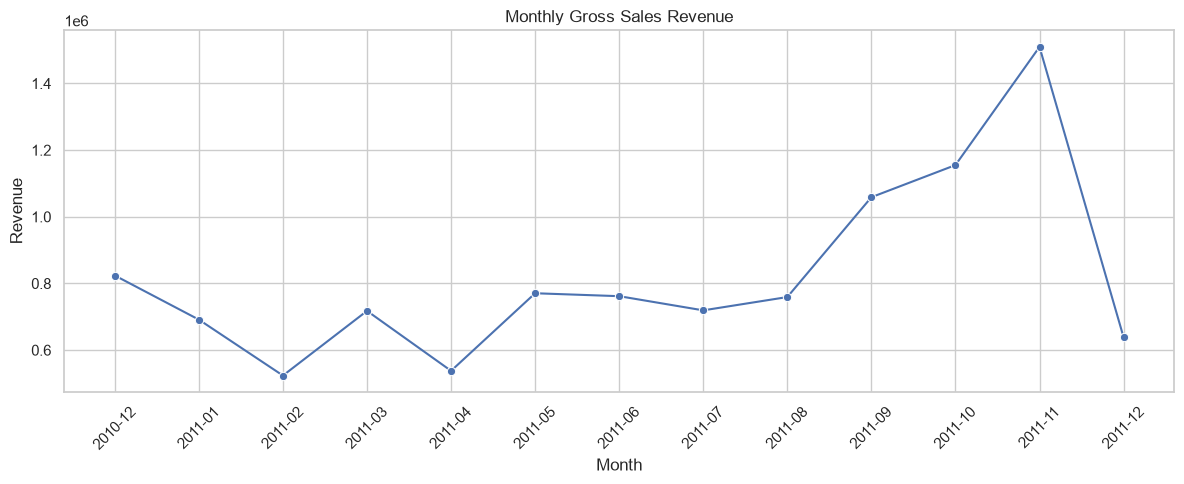

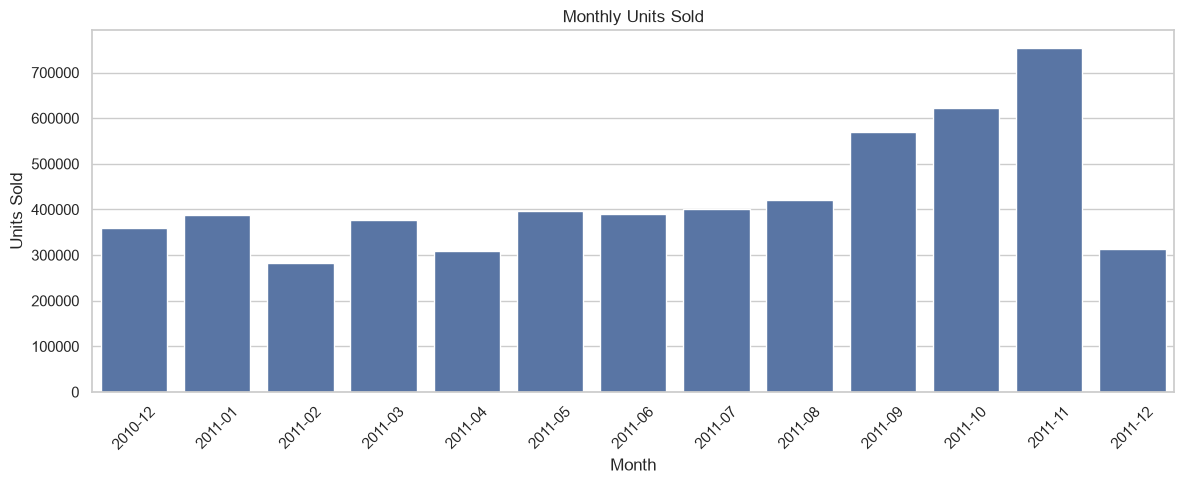

In [7]:

# Select ordinary positive sales records
sales_df = eda_df.loc[
    (eda_df["Quantity"] > 0) &
    (eda_df["UnitPrice"] > 0) &
    (~eda_df["IsCancellation"])
].copy()

print("Positive sales rows:", len(sales_df))

# Extract date features
sales_df["Date"] = sales_df["InvoiceDate"].dt.date
sales_df["Month"] = sales_df["InvoiceDate"].dt.to_period("M")

# Monthly analysis
monthly_sales = (
    sales_df.groupby("Month")
    .agg(
        Revenue=("LineValue", "sum"),
        UnitsSold=("Quantity", "sum"),
        Transactions=("InvoiceNo", "nunique")
    )
    .reset_index()
)

monthly_sales["Month"] = monthly_sales["Month"].astype(str)

display(monthly_sales)

# Plot monthly revenue
plt.figure(figsize=(12, 5))
sns.lineplot(
    data=monthly_sales,
    x="Month",
    y="Revenue",
    marker="o"
)
plt.title("Monthly Gross Sales Revenue")
plt.xlabel("Month")
plt.ylabel("Revenue")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

# Plot monthly units sold
plt.figure(figsize=(12, 5))
sns.barplot(
    data=monthly_sales,
    x="Month",
    y="UnitsSold"
)
plt.title("Monthly Units Sold")
plt.xlabel("Month")
plt.ylabel("Units Sold")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


,StockCode,Description,UnitsSold,Revenue
2390,23843,"PAPER CRAFT , LITTLE BIRDIE",80995,168469.60
1945,23166,MEDIUM CERAMIC TOP STORAGE JAR,78033,81700.92
1034,22197,SMALL POPCORN HOLDER,56921,51354.02
2562,84077,WORLD WAR 2 GLIDERS ASSTD DESIGNS,55047,13841.85
3528,85099B,JUMBO BAG RED RETROSPOT,48474,94340.05
3539,85123A,WHITE HANGING HEART T-LIGHT HOLDER,37660,104518.80
2666,84879,ASSORTED COLOUR BIRD ORNAMENT,36461,59094.93
364,21212,PACK OF 72 RETROSPOT CAKE CASES,36419,21259.10
1867,23084,RABBIT NIGHT LIGHT,30788,66964.99
1299,22492,MINI PAINT SET VINTAGE,26633,16937.82


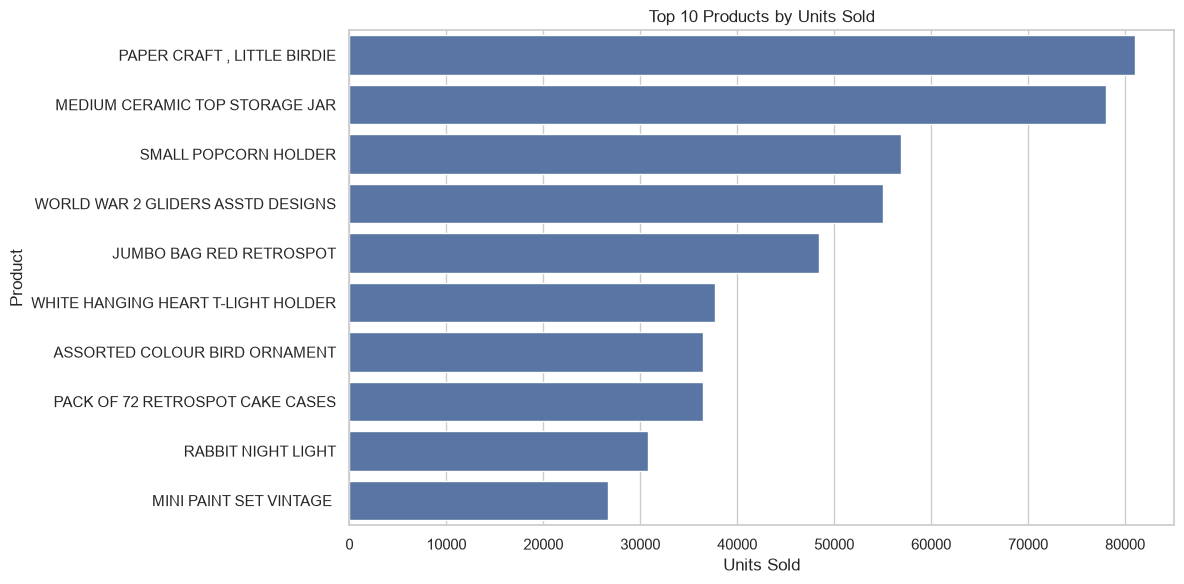

,StockCode,Description,UnitsSold,Revenue
3911,DOT,DOTCOM POSTAGE,706,206248.77
1235,22423,REGENCY CAKESTAND 3 TIER,13879,174484.74
2390,23843,"PAPER CRAFT , LITTLE BIRDIE",80995,168469.60
3539,85123A,WHITE HANGING HEART T-LIGHT HOLDER,37660,104518.80
2468,47566,PARTY BUNTING,18295,99504.33
3528,85099B,JUMBO BAG RED RETROSPOT,48474,94340.05
1945,23166,MEDIUM CERAMIC TOP STORAGE JAR,78033,81700.92
3912,M,Manual,7224,78110.27
3914,POST,POSTAGE,3150,78101.88
1867,23084,RABBIT NIGHT LIGHT,30788,66964.99


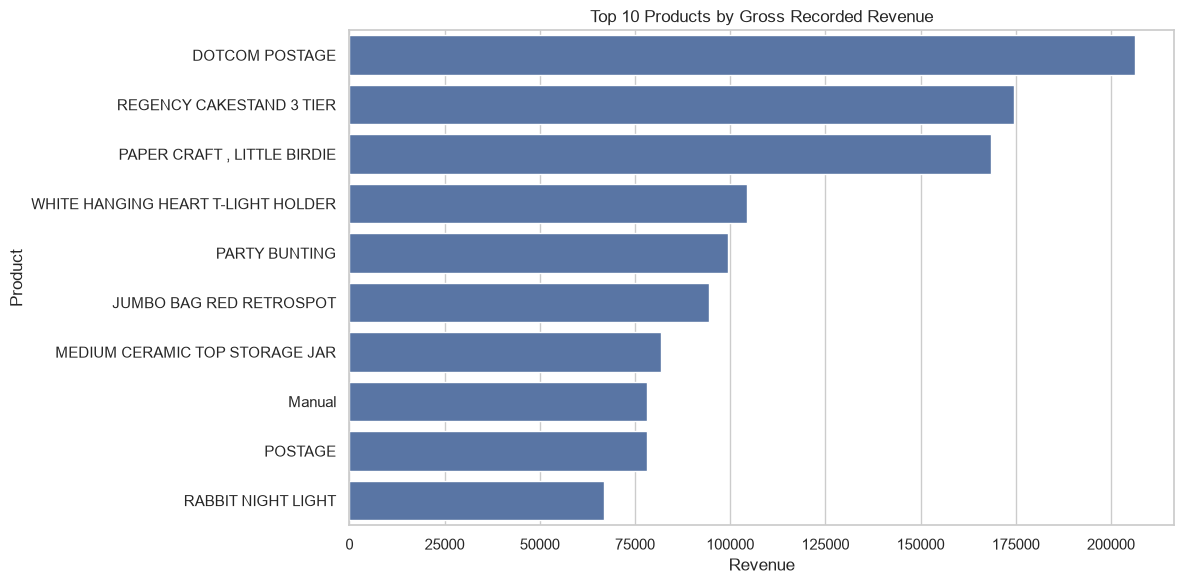

In [8]:

# Aggregate product performance
product_sales = (
    sales_df.groupby("StockCode")
    .agg(
        UnitsSold=("Quantity", "sum"),
        Revenue=("LineValue", "sum"),
        Transactions=("InvoiceNo", "nunique"),
        Description=("Description", "first")
    )
    .reset_index()
)

# Top 10 by quantity
top_quantity = product_sales.nlargest(10, "UnitsSold")

display(
    top_quantity[
        ["StockCode", "Description", "UnitsSold", "Revenue"]
    ]
)

plt.figure(figsize=(12, 6))
sns.barplot(
    data=top_quantity,
    x="UnitsSold",
    y="Description"
)
plt.title("Top 10 Products by Units Sold")
plt.xlabel("Units Sold")
plt.ylabel("Product")
plt.tight_layout()
plt.show()

# Top 10 by revenue
top_revenue = product_sales.nlargest(10, "Revenue")

display(
    top_revenue[
        ["StockCode", "Description", "UnitsSold", "Revenue"]
    ]
)

plt.figure(figsize=(12, 6))
sns.barplot(
    data=top_revenue,
    x="Revenue",
    y="Description"
)
plt.title("Top 10 Products by Gross Recorded Revenue")
plt.xlabel("Revenue")
plt.ylabel("Product")
plt.tight_layout()
plt.show()


,Country,Revenue,UnitsSold,Transactions
36,United Kingdom,9025222.084,4662390,18019
24,Netherlands,285446.340,200361,94
10,EIRE,283453.960,147173,288
14,Germany,228867.140,119261,457
13,France,209715.110,112103,392
0,Australia,138521.310,83901,57
31,Spain,61577.110,27940,90
33,Switzerland,57089.900,30629,54
3,Belgium,41196.340,23237,98
32,Sweden,38378.330,36083,36


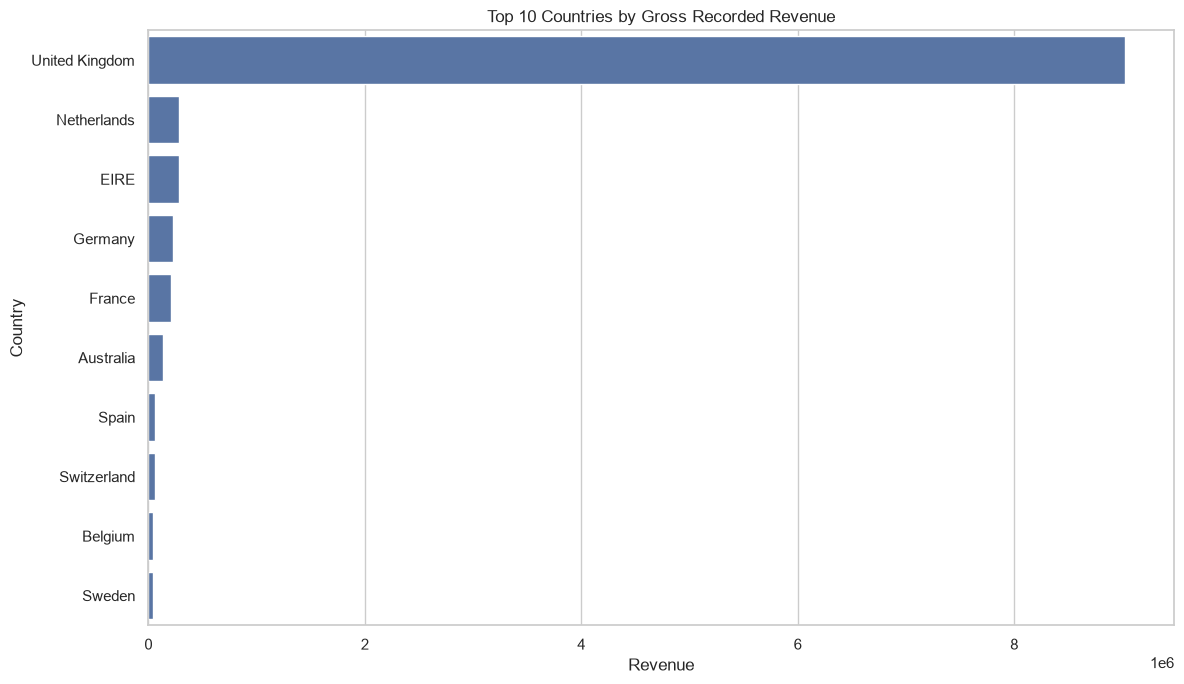

In [9]:

country_sales = (
    sales_df.groupby("Country")
    .agg(
        Revenue=("LineValue", "sum"),
        UnitsSold=("Quantity", "sum"),
        Transactions=("InvoiceNo", "nunique")
    )
    .reset_index()
    .sort_values("Revenue", ascending=False)
)

display(country_sales.head(15))

plt.figure(figsize=(12, 7))
sns.barplot(
    data=country_sales.head(10),
    x="Revenue",
    y="Country"
)
plt.title("Top 10 Countries by Gross Recorded Revenue")
plt.xlabel("Revenue")
plt.ylabel("Country")
plt.tight_layout()
plt.show()


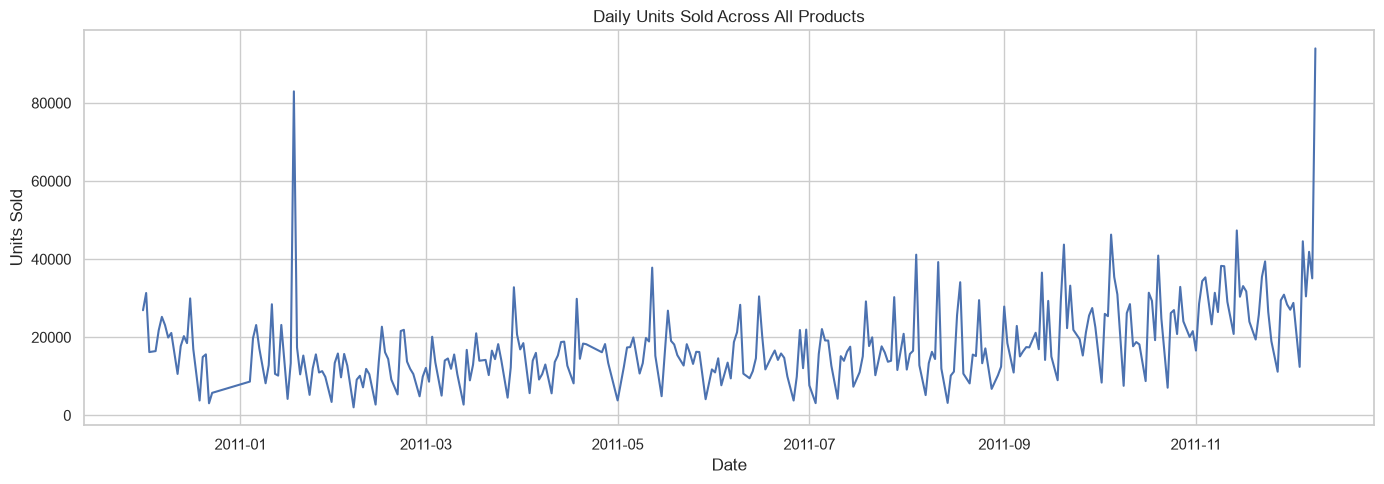

,DayOfWeek,UnitsSold,Revenue
0,Monday,873332.0,1779575.041
1,Tuesday,1115208.0,2178632.611
2,Wednesday,1027431.0,1851147.810
3,Thursday,1209617.0,2203161.240
4,Friday,891784.0,1840340.231
5,Saturday,NaN,NaN
6,Sunday,471004.0,813827.611


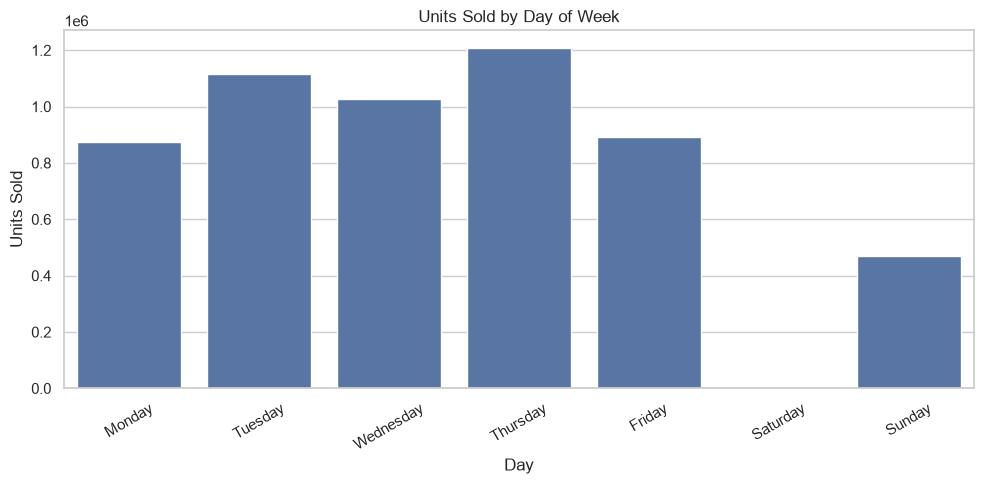

In [10]:

# Daily total sales
daily_sales = (
    sales_df.groupby(sales_df["InvoiceDate"].dt.date)
    .agg(
        Revenue=("LineValue", "sum"),
        UnitsSold=("Quantity", "sum"),
        Transactions=("InvoiceNo", "nunique")
    )
    .reset_index()
    .rename(columns={"InvoiceDate": "Date"})
)

daily_sales["Date"] = pd.to_datetime(daily_sales["Date"])

plt.figure(figsize=(14, 5))
sns.lineplot(
    data=daily_sales,
    x="Date",
    y="UnitsSold"
)
plt.title("Daily Units Sold Across All Products")
plt.xlabel("Date")
plt.ylabel("Units Sold")
plt.tight_layout()
plt.show()

# Weekday demand patterns
sales_df["DayOfWeek"] = (
    sales_df["InvoiceDate"].dt.day_name()
)

weekday_order = [
    "Monday", "Tuesday", "Wednesday",
    "Thursday", "Friday", "Saturday", "Sunday"
]

weekday_sales = (
    sales_df.groupby("DayOfWeek")
    .agg(
        UnitsSold=("Quantity", "sum"),
        Revenue=("LineValue", "sum")
    )
    .reindex(weekday_order)
    .reset_index()
)

display(weekday_sales)

plt.figure(figsize=(10, 5))
sns.barplot(
    data=weekday_sales,
    x="DayOfWeek",
    y="UnitsSold"
)
plt.title("Units Sold by Day of Week")
plt.xlabel("Day")
plt.ylabel("Units Sold")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()


In [11]:

# Start from the original data
clean_df = df.copy()

# Standardize stock codes for inspection
clean_df["StockCode"] = clean_df["StockCode"].astype(str).str.strip()

# Identify codes that don't resemble a numeric product code
# with an optional alphabetic suffix.
standard_code_mask = clean_df["StockCode"].str.fullmatch(
    r"\d+[A-Za-z]?"
)

unusual_codes = (
    clean_df.loc[~standard_code_mask]
    .groupby(["StockCode", "Description"], dropna=False)
    .agg(
        Rows=("InvoiceNo", "size"),
        TotalQuantity=("Quantity", "sum"),
        TotalValue=(
            "UnitPrice",
            lambda prices: (
                prices * clean_df.loc[prices.index, "Quantity"]
            ).sum()
        )
    )
    .reset_index()
    .sort_values("Rows", ascending=False)
)

print("Unusual code groups:", len(unusual_codes))
display(unusual_codes.head(40))


Unusual code groups: 46


,StockCode,Description,Rows,TotalQuantity,TotalValue
34,POST,POSTAGE,1252,3003,66230.640
30,DOT,DOTCOM POSTAGE,709,707,206245.480
32,M,Manual,571,3164,-68674.190
0,15056BL,EDWARDIAN PARASOL BLACK,326,2714,15176.340
7,C2,CARRIAGE,143,140,6986.000
10,D,Discount,77,-1194,-5696.220
36,S,SAMPLES,63,-59,-3049.390
1,15056bl,EDWARDIAN PARASOL BLACK,62,87,1086.880
6,BANK CHARGES,Bank Charges,37,-13,-7175.639
4,AMAZONFEE,AMAZON FEE,34,-30,-221520.500


In [12]:

# 1. Remove exact duplicate transaction rows
dedup_df = df.drop_duplicates().copy()

print("Original rows:", len(df))
print("Rows after deduplication:", len(dedup_df))
print("Exact duplicate rows removed:", len(df) - len(dedup_df))

# 2. Normalize invoice and product codes
dedup_df["InvoiceNo"] = dedup_df["InvoiceNo"].astype(str).str.strip()
dedup_df["StockCode"] = dedup_df["StockCode"].astype(str).str.strip()

# 3. Identify cancellations
dedup_df["IsCancellation"] = (
    dedup_df["InvoiceNo"].str.upper().str.startswith("C")
)

# 4. Keep positive sales transactions
positive_sales = dedup_df.loc[
    (~dedup_df["IsCancellation"]) &
    (dedup_df["Quantity"] > 0) &
    (dedup_df["UnitPrice"] > 0)
].copy()

positive_sales["LineValue"] = (
    positive_sales["Quantity"] * positive_sales["UnitPrice"]
)

print("\nRows after initial sales filtering:", len(positive_sales))
print("Unique product codes:", positive_sales["StockCode"].nunique())
print("Gross recorded sales value:", round(positive_sales["LineValue"].sum(), 2))

display(positive_sales.head())


Original rows: 541909
Rows after deduplication: 536641
Exact duplicate rows removed: 5268

Rows after initial sales filtering: 524878
Unique product codes: 3922
Gross recorded sales value: 10642110.8


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,IsCancellation,LineValue
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom,False,15.30
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,False,20.34
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom,False,22.00
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,False,20.34
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,False,20.34


In [13]:

# Apply the merchandise-code screening rule
# only after reviewing unusual_codes from Step 3.1.
merchandise_mask = positive_sales["StockCode"].str.fullmatch(
    r"\d+[A-Za-z]?"
)

product_sales_df = positive_sales.loc[merchandise_mask].copy()

print("Rows before merchandise filter:", len(positive_sales))
print("Rows after merchandise filter:", len(product_sales_df))
print("Products retained:", product_sales_df["StockCode"].nunique())

# Inspect unusually large individual transaction quantities
display(
    product_sales_df.nlargest(
        10, "Quantity"
    )[
        ["InvoiceNo", "StockCode", "Description",
         "Quantity", "InvoiceDate", "UnitPrice"]
    ]
)


Rows before merchandise filter: 524878
Rows after merchandise filter: 522121
Products retained: 3898


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice
540421,581483,23843,"PAPER CRAFT , LITTLE BIRDIE",80995,2011-12-09 09:15:00,2.08
61619,541431,23166,MEDIUM CERAMIC TOP STORAGE JAR,74215,2011-01-18 10:01:00,1.04
421632,573008,84077,WORLD WAR 2 GLIDERS ASSTD DESIGNS,4800,2011-10-27 12:26:00,0.21
206121,554868,22197,SMALL POPCORN HOLDER,4300,2011-05-27 10:52:00,0.72
97432,544612,22053,EMPIRE DESIGN ROSETTE,3906,2011-02-22 10:43:00,0.82
270885,560599,18007,ESSENTIAL BALM 3.5g TIN IN ENVELOPE,3186,2011-07-19 17:04:00,0.06
52711,540815,21108,FAIRY CAKE FLANNEL ASSORTED COLOUR,3114,2011-01-11 12:55:00,2.10
160546,550461,21108,FAIRY CAKE FLANNEL ASSORTED COLOUR,3114,2011-04-18 13:20:00,2.10
433788,573995,16014,SMALL CHINESE STYLE SCISSOR,3000,2011-11-02 11:24:00,0.32
4945,536830,84077,WORLD WAR 2 GLIDERS ASSTD DESIGNS,2880,2010-12-02 17:38:00,0.18


In [14]:

# Create a calendar date column
product_sales_df["Date"] = (
    product_sales_df["InvoiceDate"].dt.normalize()
)

# Daily product demand
daily_demand = (
    product_sales_df
    .groupby(["Date", "StockCode"], as_index=False)
    .agg(
        UnitsSold=("Quantity", "sum"),
        DailyRevenue=("LineValue", "sum"),
        TransactionCount=("InvoiceNo", "nunique")
    )
    .sort_values(["StockCode", "Date"])
    .reset_index(drop=True)
)

print("Daily product-demand shape:", daily_demand.shape)
print("Date range:", daily_demand["Date"].min(),
      "to", daily_demand["Date"].max())
print("Unique products:", daily_demand["StockCode"].nunique())

display(daily_demand.head(10))


Daily product-demand shape: (275047, 5)
Date range: 2010-12-01 00:00:00 to 2011-12-09 00:00:00
Unique products: 3898


,Date,StockCode,UnitsSold,DailyRevenue,TransactionCount
0,2010-12-01,10002,60,51.00,2
1,2010-12-02,10002,1,0.85,1
2,2010-12-03,10002,8,12.47,3
3,2010-12-05,10002,1,0.85,1
4,2010-12-06,10002,25,22.06,2
5,2010-12-07,10002,8,13.28,3
6,2010-12-08,10002,13,11.86,2
7,2010-12-09,10002,44,39.02,5
8,2010-12-10,10002,48,40.80,2
9,2010-12-13,10002,27,25.38,3


In [15]:

# Calendar features
daily_demand["DayOfWeek"] = daily_demand["Date"].dt.dayofweek
daily_demand["Month"] = daily_demand["Date"].dt.month
daily_demand["DayOfMonth"] = daily_demand["Date"].dt.day

# Historical demand features, calculated separately per product
daily_demand = daily_demand.sort_values(
    ["StockCode", "Date"]
).copy()

grouped_demand = daily_demand.groupby("StockCode")["UnitsSold"]

daily_demand["Lag_1"] = grouped_demand.shift(1)
daily_demand["Lag_7"] = grouped_demand.shift(7)
daily_demand["Lag_14"] = grouped_demand.shift(14)

# Shift first, then calculate rolling averages.
# This prevents today's target from entering today's features.
daily_demand["RollingMean_7"] = (
    daily_demand.groupby("StockCode")["UnitsSold"]
    .transform(lambda s: s.shift(1).rolling(7).mean())
)

daily_demand["RollingMean_14"] = (
    daily_demand.groupby("StockCode")["UnitsSold"]
    .transform(lambda s: s.shift(1).rolling(14).mean())
)

display(daily_demand.head(20))


,Date,StockCode,UnitsSold,DailyRevenue,TransactionCount,DayOfWeek,Month,DayOfMonth,Lag_1,Lag_7,Lag_14,RollingMean_7,RollingMean_14
0,2010-12-01,10002,60,51.00,2,2,12,1,NaN,NaN,NaN,NaN,NaN
1,2010-12-02,10002,1,0.85,1,3,12,2,60.0,NaN,NaN,NaN,NaN
2,2010-12-03,10002,8,12.47,3,4,12,3,1.0,NaN,NaN,NaN,NaN
3,2010-12-05,10002,1,0.85,1,6,12,5,8.0,NaN,NaN,NaN,NaN
4,2010-12-06,10002,25,22.06,2,0,12,6,1.0,NaN,NaN,NaN,NaN
5,2010-12-07,10002,8,13.28,3,1,12,7,25.0,NaN,NaN,NaN,NaN
6,2010-12-08,10002,13,11.86,2,2,12,8,8.0,NaN,NaN,NaN,NaN
7,2010-12-09,10002,44,39.02,5,3,12,9,13.0,60.0,NaN,16.571429,NaN
8,2010-12-10,10002,48,40.80,2,4,12,10,44.0,1.0,NaN,14.285714,NaN
9,2010-12-13,10002,27,25.38,3,0,12,13,48.0,8.0,NaN,21.000000,NaN


In [16]:

# Start from the deduplicated transactions
tx = dedup_df.copy()

# Normalize product codes so case differences don't split a product
tx["StockCode"] = (
    tx["StockCode"].astype(str).str.strip().str.upper()
)

# Exclude known non-merchandise transaction codes
non_merchandise_codes = {
    "POST", "DOT", "M", "C2", "D", "S",
    "BANK CHARGES", "AMAZONFEE", "CRUK", "B",
    "PADS"
}

# Exclude non-product adjustment descriptions
description = tx["Description"].fillna("").str.strip().str.lower()

valid_description = ~description.isin({
    "unsaleable, destroyed.",
    "ebay"
})

# Keep positive outgoing sales for this initial experiment
tx["IsCancellation"] = (
    tx["InvoiceNo"].astype(str).str.upper().str.startswith("C")
)

tx = tx.loc[
    (~tx["IsCancellation"]) &
    (tx["Quantity"] > 0) &
    (tx["UnitPrice"] > 0) &
    (~tx["StockCode"].isin(non_merchandise_codes)) &
    (~tx["StockCode"].str.startswith("GIFT_")) &
    valid_description
].copy()

tx["Date"] = tx["InvoiceDate"].dt.normalize()
tx["LineValue"] = tx["Quantity"] * tx["UnitPrice"]

print("Eligible transaction rows:", len(tx))
print("Eligible product codes:", tx["StockCode"].nunique())
print("Date range:", tx["Date"].min(), "to", tx["Date"].max())

# Audit exceptionally large transactions
display(
    tx.nlargest(10, "Quantity")[
        ["InvoiceNo", "StockCode", "Description",
         "Quantity", "InvoiceDate", "UnitPrice"]
    ]
)


Eligible transaction rows: 522537
Eligible product codes: 3798
Date range: 2010-12-01 00:00:00 to 2011-12-09 00:00:00


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice
540421,581483,23843,"PAPER CRAFT , LITTLE BIRDIE",80995,2011-12-09 09:15:00,2.08
61619,541431,23166,MEDIUM CERAMIC TOP STORAGE JAR,74215,2011-01-18 10:01:00,1.04
421632,573008,84077,WORLD WAR 2 GLIDERS ASSTD DESIGNS,4800,2011-10-27 12:26:00,0.21
206121,554868,22197,SMALL POPCORN HOLDER,4300,2011-05-27 10:52:00,0.72
97432,544612,22053,EMPIRE DESIGN ROSETTE,3906,2011-02-22 10:43:00,0.82
270885,560599,18007,ESSENTIAL BALM 3.5g TIN IN ENVELOPE,3186,2011-07-19 17:04:00,0.06
52711,540815,21108,FAIRY CAKE FLANNEL ASSORTED COLOUR,3114,2011-01-11 12:55:00,2.10
160546,550461,21108,FAIRY CAKE FLANNEL ASSORTED COLOUR,3114,2011-04-18 13:20:00,2.10
433788,573995,16014,SMALL CHINESE STYLE SCISSOR,3000,2011-11-02 11:24:00,0.32
4945,536830,84077,WORLD WAR 2 GLIDERS ASSTD DESIGNS,2880,2010-12-02 17:38:00,0.18


In [17]:

# Daily product sales from eligible transactions
daily_observed = (
    tx.groupby(["Date", "StockCode"], as_index=False)
    .agg(UnitsSold=("Quantity", "sum"))
    .sort_values(["StockCode", "Date"])
)

end_date = tx["Date"].max()
test_start = end_date - pd.Timedelta(days=29)

# Product selection uses training-period data only
selection_data = daily_observed.loc[
    daily_observed["Date"] < test_start
]

top_products = (
    selection_data.groupby("StockCode")["UnitsSold"]
    .sum()
    .nlargest(50)
    .index
)

print("Test period:", test_start.date(), "to", end_date.date())
print("Selected products:", len(top_products))

# Keep only the selected products
selected_sales = daily_observed.loc[
    daily_observed["StockCode"].isin(top_products)
].copy()

display(
    selected_sales.groupby("StockCode")["UnitsSold"]
    .sum()
    .sort_values(ascending=False)
    .head(10)
)


Test period: 2011-11-10 to 2011-12-09
Selected products: 50


StockCode
23166     78033
22197     56898
84077     54951
85099B    48371
85123A    37933
21212     36396
84879     36362
23084     30739
22492     26633
22616     26119
Name: UnitsSold, dtype: int64

In [18]:

# Build a continuous daily calendar for each selected product
calendar_parts = []

for stock_code in top_products:
    product_history = selected_sales.loc[
        selected_sales["StockCode"] == stock_code
    ]

    first_date = product_history["Date"].min()

    product_calendar = pd.DataFrame({
        "Date": pd.date_range(
            start=first_date,
            end=end_date,
            freq="D"
        )
    })

    product_calendar["StockCode"] = stock_code
    calendar_parts.append(product_calendar)

calendar_df = pd.concat(calendar_parts, ignore_index=True)

# Merge observed sales onto the calendar
model_df = calendar_df.merge(
    selected_sales,
    on=["Date", "StockCode"],
    how="left"
)

model_df["UnitsSold"] = model_df["UnitsSold"].fillna(0)

model_df = model_df.sort_values(
    ["StockCode", "Date"]
).reset_index(drop=True)

print("Calendar-complete dataset:", model_df.shape)
print("Missing daily targets:", model_df["UnitsSold"].isna().sum())
print("Zero-sales product-days:", (model_df["UnitsSold"] == 0).sum())

display(model_df.head(15))


Calendar-complete dataset: (17903, 3)
Missing daily targets: 0
Zero-sales product-days: 5647


,Date,StockCode,UnitsSold
0,2010-12-02,15036,48.0
1,2010-12-03,15036,15.0
2,2010-12-04,15036,0.0
3,2010-12-05,15036,12.0
4,2010-12-06,15036,4.0
5,2010-12-07,15036,0.0
6,2010-12-08,15036,13.0
7,2010-12-09,15036,1.0
8,2010-12-10,15036,3.0
9,2010-12-11,15036,0.0


In [19]:

# Calendar features
model_df["DayOfWeek"] = model_df["Date"].dt.dayofweek
model_df["Month"] = model_df["Date"].dt.month
model_df["DayOfMonth"] = model_df["Date"].dt.day

grouped = model_df.groupby("StockCode")["UnitsSold"]

# Demand from previous calendar days
model_df["Lag_1"] = grouped.shift(1)
model_df["Lag_7"] = grouped.shift(7)
model_df["Lag_14"] = grouped.shift(14)

# Rolling features use only earlier days
model_df["RollingMean_7"] = (
    model_df.groupby("StockCode")["UnitsSold"]
    .transform(lambda s: s.shift(1).rolling(7).mean())
)

model_df["RollingMean_14"] = (
    model_df.groupby("StockCode")["UnitsSold"]
    .transform(lambda s: s.shift(1).rolling(14).mean())
)

# Remove rows that lack sufficient historical data
model_df = model_df.dropna(
    subset=["Lag_1", "Lag_7", "Lag_14",
            "RollingMean_7", "RollingMean_14"]
).reset_index(drop=True)

print("Final modeling dataset:", model_df.shape)
display(model_df.head())


Final modeling dataset: (17203, 11)


,Date,StockCode,UnitsSold,DayOfWeek,Month,DayOfMonth,Lag_1,Lag_7,Lag_14,RollingMean_7,RollingMean_14
0,2010-12-16,15036,12.0,3,12,16,0.0,1.0,48.0,2.857143,8.000000
1,2010-12-17,15036,7.0,4,12,17,12.0,3.0,15.0,4.428571,5.428571
2,2010-12-18,15036,0.0,5,12,18,7.0,0.0,0.0,5.000000,4.857143
3,2010-12-19,15036,0.0,6,12,19,0.0,0.0,12.0,5.000000,4.857143
4,2010-12-20,15036,6.0,0,12,20,0.0,4.0,4.0,5.000000,4.000000


In [20]:

feature_cols = [
    "DayOfWeek",
    "Month",
    "DayOfMonth",
    "Lag_1",
    "Lag_7",
    "Lag_14",
    "RollingMean_7",
    "RollingMean_14"
]

train_df = model_df.loc[
    model_df["Date"] < test_start
].copy()

test_df = model_df.loc[
    model_df["Date"] >= test_start
].copy()

print("Training rows:", len(train_df))
print("Testing rows:", len(test_df))
print("Training ends:", train_df["Date"].max())
print("Testing starts:", test_df["Date"].min())

# Simple forecasting baselines
test_df["Naive_Lag1"] = test_df["Lag_1"]
test_df["Mean_7Day"] = test_df["RollingMean_7"]

def calculate_metrics(actual, predicted):
    actual = np.asarray(actual)
    predicted = np.asarray(predicted)

    return {
        "MAE": np.mean(np.abs(actual - predicted)),
        "RMSE": np.sqrt(np.mean((actual - predicted) ** 2)),
        "WAPE_percent": (
            np.sum(np.abs(actual - predicted))
            / max(np.sum(np.abs(actual)), 1e-9)
            * 100
        )
    }

baseline_results = pd.DataFrame([
    {
        "Model": "Previous day",
        **calculate_metrics(
            test_df["UnitsSold"], test_df["Naive_Lag1"]
        )
    },
    {
        "Model": "Previous 7-day mean",
        **calculate_metrics(
            test_df["UnitsSold"], test_df["Mean_7Day"]
        )
    }
])

display(baseline_results.round(3))


Training rows: 15703
Testing rows: 1500
Training ends: 2011-11-09 00:00:00
Testing starts: 2011-11-10 00:00:00


,Model,MAE,RMSE,WAPE_percent
0,Previous day,91.611,219.774,113.898
1,Previous 7-day mean,72.400,162.837,90.013


In [22]:

# STEP 4.1 — Rebuild the calendar-complete dataset
# Uses selected_sales from the previous section.

import pandas as pd
import numpy as np

end_date = selected_sales["Date"].max()
test_start = end_date - pd.Timedelta(days=29)

calendar_parts = []

for code, group in selected_sales.groupby("StockCode"):
    first_date = group["Date"].min()

    calendar_parts.append(
        pd.DataFrame({
            "Date": pd.date_range(
                start=first_date,
                end=end_date,
                freq="D"
            ),
            "StockCode": code
        })
    )

calendar_df = pd.concat(calendar_parts, ignore_index=True)

calendar_df = calendar_df.merge(
    selected_sales[["Date", "StockCode", "UnitsSold"]],
    on=["Date", "StockCode"],
    how="left"
)

calendar_df["UnitsSold"] = (
    calendar_df["UnitsSold"].fillna(0)
)

calendar_df = calendar_df.sort_values(
    ["StockCode", "Date"]
).reset_index(drop=True)

print("Calendar dataset:", calendar_df.shape)
print("Date range:", calendar_df["Date"].min(), "to",
      calendar_df["Date"].max())

# STEP 4.2 — Inspect largest product-day demand values

print("\nTop 20 product-days by units sold:")

display(
    calendar_df.nlargest(20, "UnitsSold")[
        ["Date", "StockCode", "UnitsSold"]
    ]
)


# STEP 4.3 — Detect unusual daily demand values

audited_df = calendar_df.copy()

# Calculate each product's own quartiles
q1 = audited_df.groupby("StockCode")["UnitsSold"].transform(
    lambda s: s.quantile(0.25)
)

q3 = audited_df.groupby("StockCode")["UnitsSold"].transform(
    lambda s: s.quantile(0.75)
)

iqr = q3 - q1

# Flag unusually high values; do not remove them yet
audited_df["OutlierFlag"] = (
    audited_df["UnitsSold"] > q3 + 3 * iqr
)

outlier_days = audited_df.loc[
    audited_df["OutlierFlag"]
].copy()

print("Flagged product-days:", len(outlier_days))

display(
    outlier_days.nlargest(20, "UnitsSold")[
        ["Date", "StockCode", "UnitsSold"]
    ].reset_index(drop=True)
)

# How much does the largest demand spike exceed normal demand?
for code in ["23166", "84077", "22197"]:
    product_data = audited_df.loc[
        audited_df["StockCode"] == code
    ]

    print(f"\nProduct: {code}")
    print("Median daily demand:", product_data["UnitsSold"].median())
    print("Maximum daily demand:", product_data["UnitsSold"].max())
    print("Days with sales:", (product_data["UnitsSold"] > 0).sum())


Calendar dataset: (17903, 3)
Date range: 2010-12-01 00:00:00 to 2011-12-09 00:00:00

Top 20 product-days by units sold:


,Date,StockCode,UnitsSold
11802,2011-01-18,23166,74215.0
14123,2011-10-27,84077,4848.0
6908,2011-05-27,22197,4314.0
14787,2011-08-04,84879,3359.0
13794,2010-12-02,84077,3264.0
17570,2011-01-11,85123A,3114.0
7103,2011-12-08,22197,3111.0
709,2011-11-02,16014,3020.0
5408,2011-05-23,21977,2724.0
11758,2011-10-27,23084,2647.0


Flagged product-days: 824


,Date,StockCode,UnitsSold
0,2011-01-18,23166,74215.0
1,2011-10-27,84077,4848.0
2,2011-05-27,22197,4314.0
3,2011-08-04,84879,3359.0
4,2010-12-02,84077,3264.0
5,2011-01-11,85123A,3114.0
6,2011-12-08,22197,3111.0
7,2011-11-02,16014,3020.0
8,2011-05-23,21977,2724.0
9,2011-10-27,23084,2647.0



Product: 23166
Median daily demand: 0.0
Maximum daily demand: 74215.0
Days with sales: 125

Product: 84077
Median daily demand: 48.0
Maximum daily demand: 4848.0
Days with sales: 235

Product: 22197
Median daily demand: 48.0
Maximum daily demand: 4314.0
Days with sales: 294


In [24]:

# STEP 4.4 — Compare time-series forecasting models

from statsmodels.tsa.holtwinters import ExponentialSmoothing

forecast_horizon = 30
results = []
forecast_rows = []

for code, group in calendar_df.groupby("StockCode"):
    group = group.sort_values("Date").copy()

    train = group[group["Date"] < test_start]
    test = group[group["Date"] >= test_start]

    y_train = train["UnitsSold"].astype(float).to_numpy()
    y_test = test["UnitsSold"].astype(float).to_numpy()

    if len(y_train) < 28 or len(y_test) != forecast_horizon:
        continue

    # Model 1: Seasonal naive — repeat the last 7 days
    seasonal_pattern = y_train[-7:]
    pred_seasonal = np.resize(
        seasonal_pattern, forecast_horizon
    )

    # Model 2: Average demand over the last 7 days
    pred_mean7 = np.full(
        forecast_horizon, np.mean(y_train[-7:])
    )

    # Model 3: Holt-Winters with weekly seasonality
    try:
        hw_model = ExponentialSmoothing(
            y_train,
            trend=None,
            seasonal="add",
            seasonal_periods=7,
            initialization_method="estimated"
        ).fit(optimized=True)

        pred_hw = hw_model.forecast(forecast_horizon)
        pred_hw = np.maximum(pred_hw, 0)

    except Exception as e:
        print(f"Holt-Winters failed for product {code}: {e}")
        pred_hw = np.full(
            forecast_horizon, np.nan
        )

    predictions = {
        "Seasonal Naive": pred_seasonal,
        "Previous 7-day Mean": pred_mean7,
        "Holt-Winters": pred_hw
    }

    for model_name, pred in predictions.items():
        if np.isnan(pred).any():
            continue

        errors = y_test - pred

        results.append({
            "StockCode": code,
            "Model": model_name,
            "MAE": np.mean(np.abs(errors)),
            "RMSE": np.sqrt(np.mean(errors ** 2)),
            "AbsoluteErrorSum": np.sum(np.abs(errors)),
            "ActualUnits": np.sum(y_test)
        })

        for date, actual, predicted in zip(
            test["Date"], y_test, pred
        ):
            forecast_rows.append({
                "Date": date,
                "StockCode": code,
                "Model": model_name,
                "ActualUnits": actual,
                "PredictedUnits": predicted
            })

results_df = pd.DataFrame(results)
forecasts_df = pd.DataFrame(forecast_rows)

# Overall metrics across all product-days
overall = (
    results_df.groupby("Model")
    .agg(
        MAE=("AbsoluteErrorSum", "sum"),
        TotalActual=("ActualUnits", "sum"),
        ProductCount=("StockCode", "nunique")
    )
)

# MAE must be divided by the total number of evaluated days
evaluated_days = (
    forecasts_df.groupby("Model").size()
)

overall["MAE"] = (
    overall["MAE"] / evaluated_days
)

# Calculate RMSE from all individual daily forecast errors
rmse_values = {}

for model_name, frame in forecasts_df.groupby("Model"):
    error = frame["ActualUnits"] - frame["PredictedUnits"]
    rmse_values[model_name] = np.sqrt(np.mean(error ** 2))

overall["RMSE"] = pd.Series(rmse_values)
overall["WAPE_percent"] = (
    overall["MAE"] * evaluated_days / overall["TotalActual"] * 100
)

overall = overall[
    ["ProductCount", "MAE", "RMSE", "WAPE_percent"]
].sort_values("WAPE_percent")

display(overall.round(3))


,ProductCount,MAE,RMSE,WAPE_percent
Model,,,,
Holt-Winters,50,66.432,169.901,82.593
Previous 7-day Mean,50,82.611,166.460,102.708
Seasonal Naive,50,96.579,255.879,120.074


In [25]:

# Product-level forecasting evaluation

product_metrics = forecasts_df.groupby(
    ["StockCode", "Model"]
).apply(
    lambda g: pd.Series({
        "MAE": np.mean(
            np.abs(g["ActualUnits"] - g["PredictedUnits"])
        ),
        "RMSE": np.sqrt(
            np.mean(
                (g["ActualUnits"] - g["PredictedUnits"]) ** 2
            )
        ),
        "WAPE_percent": (
            np.abs(g["ActualUnits"] - g["PredictedUnits"]).sum()
            / max(g["ActualUnits"].sum(), 1)
        ) * 100
    }),
    include_groups=False
).reset_index()

# Best model by WAPE for each product
best_models = (
    product_metrics.sort_values("WAPE_percent")
    .groupby("StockCode")
    .first()
    .reset_index()
)

print("Best model selected per product:")
display(best_models.head(15).round(2))

print("\nNumber of products won by each model:")
display(
    best_models["Model"].value_counts().to_frame("Products")
)


Best model selected per product:


,StockCode,Model,MAE,RMSE,WAPE_percent
0,15036,Seasonal Naive,17.97,31.65,98.36
1,16014,Seasonal Naive,22.23,92.50,103.41
2,17003,Previous 7-day Mean,41.03,60.82,94.97
3,20719,Seasonal Naive,25.17,38.14,55.97
4,20724,Seasonal Naive,41.57,60.36,49.23
5,20725,Holt-Winters,23.94,38.89,41.67
6,21080,Seasonal Naive,26.03,49.29,80.52
7,21212,Holt-Winters,52.79,66.68,80.96
8,21213,Previous 7-day Mean,22.06,27.48,109.40
9,21731,Holt-Winters,45.42,73.37,65.13



Number of products won by each model:


,Products
Model,
Holt-Winters,30
Seasonal Naive,14
Previous 7-day Mean,6


In [26]:

# Train on all available history and forecast future demand

future_horizon = 30
future_rows = []

for code, group in calendar_df.groupby("StockCode"):
    group = group.sort_values("Date")
    y = group["UnitsSold"].astype(float)

    if len(y) < 28:
        continue

    try:
        model = ExponentialSmoothing(
            y,
            trend=None,
            seasonal="add",
            seasonal_periods=7,
            initialization_method="estimated"
        ).fit(optimized=True)

        predictions = model.forecast(future_horizon)
        predictions = np.maximum(predictions, 0)

        future_dates = pd.date_range(
            start=group["Date"].max() + pd.Timedelta(days=1),
            periods=future_horizon,
            freq="D"
        )

        for date, predicted in zip(future_dates, predictions):
            future_rows.append({
                "Date": date,
                "StockCode": code,
                "PredictedUnits": float(predicted)
            })

    except Exception as e:
        print(f"Could not forecast {code}: {e}")

future_forecasts = pd.DataFrame(future_rows)

print("Forecast rows:", len(future_forecasts))
print(
    "Forecast dates:",
    future_forecasts["Date"].min(),
    "to",
    future_forecasts["Date"].max()
)

# Show the forecast for the top-demand product
top_product = (
    calendar_df.groupby("StockCode")["UnitsSold"]
    .sum()
    .idxmax()
)

display(
    future_forecasts[
        future_forecasts["StockCode"] == top_product
    ].head(30).round(2)
)


Forecast rows: 1500
Forecast dates: 2011-12-10 00:00:00 to 2012-01-08 00:00:00


C:\Users\ZABLAP\AppData\Local\Temp\ipykernel_7280\3905878241.py:61: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  ].head(30).round(2)


,Date,StockCode,PredictedUnits
960,2011-12-10,23166,0.0
961,2011-12-11,23166,0.0
962,2011-12-12,23166,0.0
963,2011-12-13,23166,1637.7
964,2011-12-14,23166,0.0
965,2011-12-15,23166,0.0
966,2011-12-16,23166,0.0
967,2011-12-17,23166,0.0
968,2011-12-18,23166,0.0
969,2011-12-19,23166,0.0


In [27]:

# STEP 5.1 — Create product-level demand features

import numpy as np
import pandas as pd

product_features = (
    calendar_df.groupby("StockCode")
    .agg(
        TotalUnits=("UnitsSold", "sum"),
        AverageDailyDemand=("UnitsSold", "mean"),
        MedianDailyDemand=("UnitsSold", "median"),
        DemandStd=("UnitsSold", "std"),
        MaximumDailyDemand=("UnitsSold", "max"),
        DemandQ95=("UnitsSold", lambda s: s.quantile(0.95)),
        ZeroSalesDays=("UnitsSold", lambda s: (s == 0).mean()),
        ActiveSalesDays=("UnitsSold", lambda s: (s > 0).sum())
    )
    .reset_index()
)

product_features["DemandCV"] = (
    product_features["DemandStd"]
    / product_features["AverageDailyDemand"].replace(0, np.nan)
).fillna(0)

print("Products available for clustering:", len(product_features))
display(product_features.head())


Products available for clustering: 50


,StockCode,TotalUnits,AverageDailyDemand,MedianDailyDemand,DemandStd,MaximumDailyDemand,DemandQ95,ZeroSalesDays,ActiveSalesDays,DemandCV
0,15036,23826.0,63.876676,12.0,191.584216,1846.0,424.00,0.378016,232,2.999283
1,16014,13328.0,35.636364,0.0,245.879079,3020.0,20.00,0.868984,49,6.899668
2,17003,23020.0,61.550802,0.0,183.699957,1476.0,330.30,0.588235,154,2.984526
3,20719,13290.0,35.534759,20.0,51.296464,408.0,123.35,0.264706,275,1.443557
4,20724,17761.0,47.489305,27.5,61.477855,383.0,157.75,0.235294,286,1.294562


In [28]:

# STEP 5.2 — Cluster products by demand behaviour

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans

cluster_columns = [
    "TotalUnits",
    "AverageDailyDemand",
    "DemandStd",
    "MaximumDailyDemand",
    "DemandQ95",
    "ZeroSalesDays",
    "ActiveSalesDays",
    "DemandCV"
]

# Log-transform skewed numerical features to reduce the
# influence of very large bulk orders.
X_cluster = product_features[cluster_columns].copy()

log_columns = [
    "TotalUnits",
    "AverageDailyDemand",
    "DemandStd",
    "MaximumDailyDemand",
    "DemandQ95",
    "ActiveSalesDays"
]

X_cluster[log_columns] = np.log1p(X_cluster[log_columns])
X_cluster = X_cluster.replace([np.inf, -np.inf], np.nan).fillna(0)

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_cluster)

kmeans = KMeans(
    n_clusters=4,
    random_state=42,
    n_init=10
)

product_features["DemandCluster"] = kmeans.fit_predict(X_scaled)

print("Products per cluster:")
display(
    product_features["DemandCluster"]
    .value_counts()
    .sort_index()
    .to_frame("ProductCount")
)

print("\nAverage characteristics per cluster:")
display(
    product_features.groupby("DemandCluster")[
        [
            "AverageDailyDemand",
            "ZeroSalesDays",
            "DemandCV",
            "MaximumDailyDemand"
        ]
    ].mean().round(2)
)

print("\nProducts in each cluster:")
for cluster_id in sorted(product_features["DemandCluster"].unique()):
    codes = product_features.loc[
        product_features["DemandCluster"] == cluster_id,
        "StockCode"
    ].tolist()

    print(f"Cluster {cluster_id}: {codes}")


Products per cluster:


,ProductCount
DemandCluster,
0,14
1,34
2,1
3,1



Average characteristics per cluster:


,AverageDailyDemand,ZeroSalesDays,DemandCV,MaximumDailyDemand
DemandCluster,,,,
0,96.70,0.30,2.40,2372.64
1,44.11,0.29,1.88,749.06
2,35.64,0.87,6.90,3020.00
3,239.37,0.62,17.17,74215.00



Products in each cluster:
Cluster 0: ['15036', '17003', '21212', '21915', '21977', '22197', '22492', '22616', '23084', '23203', '84077', '84879', '85099B', '85123A']
Cluster 1: ['20719', '20724', '20725', '21080', '21213', '21731', '21790', '21931', '21975', '22086', '22151', '22178', '22355', '22383', '22386', '22423', '22469', '22629', '22693', '22952', '22961', '22969', '23199', '23201', '23209', '47566', '71459', '84755', '84946', '84978', '84991', '84992', '85099C', '85099F']
Cluster 2: ['16014']
Cluster 3: ['23166']


In [29]:

# STEP 5.3 — Isolation Forest anomaly detection

from sklearn.ensemble import IsolationForest

anomaly_df = calendar_df.copy()

# Add product-level reference statistics
anomaly_df = anomaly_df.merge(
    product_features[
        ["StockCode", "MedianDailyDemand", "ZeroSalesDays"]
    ],
    on="StockCode",
    how="left"
)

# Use logarithms to reduce the effect of huge order quantities
anomaly_df["LogUnitsSold"] = np.log1p(anomaly_df["UnitsSold"])
anomaly_df["LogProductMedian"] = np.log1p(
    anomaly_df["MedianDailyDemand"]
)

# How different is today's demand from this product's median?
anomaly_df["DemandVsMedian"] = (
    anomaly_df["LogUnitsSold"]
    - anomaly_df["LogProductMedian"]
)

anomaly_features = [
    "LogUnitsSold",
    "DemandVsMedian",
    "ZeroSalesDays"
]

iso_forest = IsolationForest(
    n_estimators=200,
    contamination=0.02,
    random_state=42
)

anomaly_df["AnomalyPrediction"] = iso_forest.fit_predict(
    anomaly_df[anomaly_features]
)

anomaly_df["AnomalyScore"] = iso_forest.decision_function(
    anomaly_df[anomaly_features]
)

# -1 means flagged as an anomaly; 1 means normal
anomaly_df["IsAnomaly"] = (
    anomaly_df["AnomalyPrediction"] == -1
)

detected_anomalies = anomaly_df.loc[
    anomaly_df["IsAnomaly"]
].sort_values("AnomalyScore")

print("Product-days evaluated:", len(anomaly_df))
print("Anomalies detected:", len(detected_anomalies))

display(
    detected_anomalies[
        [
            "Date",
            "StockCode",
            "UnitsSold",
            "MedianDailyDemand",
            "AnomalyScore"
        ]
    ].head(20).reset_index(drop=True)
)


Product-days evaluated: 17903
Anomalies detected: 355


,Date,StockCode,UnitsSold,MedianDailyDemand,AnomalyScore
0,2011-11-02,16014,3020.0,0.0,-0.154445
1,2011-05-06,16014,2001.0,0.0,-0.152586
2,2011-08-24,16014,2004.0,0.0,-0.152586
3,2011-02-15,16014,1500.0,0.0,-0.145980
4,2011-09-08,16014,1000.0,0.0,-0.136344
5,2010-12-08,16014,1000.0,0.0,-0.136344
6,2011-03-23,16014,1000.0,0.0,-0.136344
7,2011-01-18,23166,74215.0,0.0,-0.122701
8,2011-05-08,16014,600.0,0.0,-0.120064
9,2011-02-11,22693,2400.0,0.0,-0.115562


In [30]:

# STEP 6.1 — Stockout risk and reorder recommendation engine

import numpy as np
import pandas as pd

# Approximate service-level multipliers for safety stock
SERVICE_LEVEL_Z = {
    0.90: 1.282,
    0.95: 1.645,
    0.99: 2.326
}

# Product descriptions for display
product_names = (
    tx.groupby("StockCode")["Description"]
    .agg(lambda s: s.dropna().iloc[0] if s.notna().any()
         else "Unknown product")
    .to_dict()
)

def assess_stockout_risk(
    stock_code,
    current_stock,
    lead_time_days=7,
    on_order=0,
    service_level=0.95
):
    """
    Estimate inventory risk using the existing 30-day forecast.

    current_stock: units currently available
    lead_time_days: days until replenishment arrives
    on_order: units already ordered but not yet received
    service_level: target service level used for safety stock

    This is a planning estimate, not a calibrated probability
    of stockout.
    """

    if current_stock < 0 or on_order < 0:
        raise ValueError("Stock values cannot be negative.")

    if not 1 <= lead_time_days <= 30:
        raise ValueError("Lead time must be between 1 and 30 days.")

    if service_level not in SERVICE_LEVEL_Z:
        raise ValueError("Choose service_level 0.90, 0.95, or 0.99.")

    forecast = future_forecasts.loc[
        future_forecasts["StockCode"] == stock_code
    ].sort_values("Date")

    if len(forecast) < lead_time_days:
        raise ValueError(
            f"Not enough forecast data for product {stock_code}."
        )

    # Demand expected before replenishment arrives
    lead_time_demand = forecast.head(
        lead_time_days
    )["PredictedUnits"].sum()

    # Historical demand variation for this product
    history = calendar_df.loc[
        calendar_df["StockCode"] == stock_code,
        "UnitsSold"
    ]

    daily_std = float(history.std()) if len(history) > 1 else 0.0
    daily_std = 0.0 if not np.isfinite(daily_std) else daily_std

    # Simplified safety-stock estimate
    safety_stock = (
        SERVICE_LEVEL_Z[service_level]
        * daily_std
        * np.sqrt(lead_time_days)
    )

    reorder_point = lead_time_demand + safety_stock
    inventory_position = current_stock + on_order

    if inventory_position <= lead_time_demand:
        risk_level = "HIGH"
    elif inventory_position <= reorder_point:
        risk_level = "MEDIUM"
    else:
        risk_level = "LOW"

    recommended_order = max(
        0,
        int(np.ceil(reorder_point - inventory_position))
    )

    return {
        "StockCode": stock_code,
        "Product": product_names.get(stock_code, "Unknown product"),
        "CurrentStock": current_stock,
        "OnOrder": on_order,
        "LeadTimeDays": lead_time_days,
        "ForecastLeadTimeDemand": round(lead_time_demand, 2),
        "SafetyStock": round(safety_stock, 2),
        "ReorderPoint": int(np.ceil(reorder_point)),
        "RiskLevel": risk_level,
        "RecommendedOrderQty": recommended_order
    }


# Example scenarios using selected products.
# These stock balances are DEMO inputs, not actual dataset values.

demo_products = (
    product_features
    .nlargest(5, "TotalUnits")["StockCode"]
    .tolist()
)

demo_results = []

for code in demo_products:
    avg_demand = product_features.loc[
        product_features["StockCode"] == code,
        "AverageDailyDemand"
    ].iloc[0]

    # Artificial starting stock for demonstrating the engine
    demo_stock = max(0, int(round(avg_demand * 5)))

    result = assess_stockout_risk(
        stock_code=code,
        current_stock=demo_stock,
        lead_time_days=7,
        on_order=0,
        service_level=0.95
    )

    demo_results.append(result)

risk_df = pd.DataFrame(demo_results)

display(risk_df)


,StockCode,Product,CurrentStock,OnOrder,LeadTimeDays,ForecastLeadTimeDemand,SafetyStock,ReorderPoint,RiskLevel,RecommendedOrderQty
0,23166,MEDIUM CERAMIC TOP STORAGE JAR,1197,0,7,1637.70,17887.22,19525,HIGH,18328
1,22197,SMALL POPCORN HOLDER,761,0,7,3307.69,1636.82,4945,HIGH,4184
2,84077,WORLD WAR 2 GLIDERS ASSTD DESIGNS,737,0,7,1150.01,1724.45,2875,HIGH,2138
3,85099B,JUMBO BAG RED RETROSPOT,647,0,7,1099.06,784.28,1884,HIGH,1237
4,85123A,WHITE HANGING HEART T-LIGHT HOLDER,507,0,7,717.64,974.78,1693,HIGH,1186


In [31]:

# Select one product to test different inventory levels

test_product = demo_products[0]

for stock_level in [0, 100, 500, 2000]:
    result = assess_stockout_risk(
        stock_code=test_product,
        current_stock=stock_level,
        lead_time_days=7,
        on_order=0,
        service_level=0.95
    )

    print(
        f"Product {test_product} | "
        f"Stock: {stock_level} | "
        f"Risk: {result['RiskLevel']} | "
        f"Reorder point: {result['ReorderPoint']} | "
        f"Suggested order: {result['RecommendedOrderQty']}"
    )


Product 23166 | Stock: 0 | Risk: HIGH | Reorder point: 19525 | Suggested order: 19525
Product 23166 | Stock: 100 | Risk: HIGH | Reorder point: 19525 | Suggested order: 19425
Product 23166 | Stock: 500 | Risk: HIGH | Reorder point: 19525 | Suggested order: 19025
Product 23166 | Stock: 2000 | Risk: MEDIUM | Reorder point: 19525 | Suggested order: 17525


In [32]:
from pathlib import Path

ARTIFACTS_DIR = Path("artifacts")
ARTIFACTS_DIR.mkdir(exist_ok=True)

# Save product-level ML features and clusters
product_features.to_csv(
    ARTIFACTS_DIR / "product_features.csv",
    index=False
)

# Save future demand forecasts
future_forecasts.to_csv(
    ARTIFACTS_DIR / "future_forecasts.csv",
    index=False
)

# Save product names
product_names_df = (
    tx.groupby("StockCode")["Description"]
    .first()
    .reset_index()
)

product_names_df.to_csv(
    ARTIFACTS_DIR / "product_names.csv",
    index=False
)

print("ML results exported successfully!")
print("Saved files:", list(ARTIFACTS_DIR.iterdir()))

ML results exported successfully!
Saved files: [WindowsPath('artifacts/future_forecasts.csv'), WindowsPath('artifacts/product_features.csv'), WindowsPath('artifacts/product_names.csv')]
